# p2.4: Rules - what the student and people learn, in words (11/24/26)

*Part of phase 2: `p2_summary.ipynb` connects this notebook with p2.1-p2.3.*

The student is a neural network: it can match people's behaviour, but what it learns is spread over a million weights.
This notebook asks whether that learning can be described in human terms - as **rules** a person could state - and
whether people and the student learn the same rules.

The approach follows **Butler, Torlak & Popović (2017)**, who synthesized interpretable strategies for Nonograms:
condition-action rules written in a small language of game concepts (*pattern*: where it applies; *condition*: when;
*action*: what to do), learned from the game's exact solutions and chosen for coverage and conciseness. Their rules
are *sound* - a nonogram deduction is never wrong. Rush Hour is planning, not deduction: the right move can look
wrong locally (moving a car away to make room), so here a rule is **scored** instead of proven - how often the moves
it picks are optimal.

`experiments/rule_mining.py` writes everything this notebook reads (`models/summary/rules/`).

## Method

**Concepts** come from AND-OR's view of a board (`rule_mining.chain`): red needs its path to the exit; a car in that
path is a *depth-1* blocker; a blocker must vacate the path cells it covers, and the cars in the way of its doing so -
either way along its lane - are *depth 2*; and so on (depth 3+ pooled). Every car in this **blocking chain** has the
cells it must vacate.

**Predicates** on a move (car, direction, steps):

| predicate | the move... |
|---|---|
| `red`, `red_exits` | is red's / solves the puzzle |
| `depth1`, `depth2`, `depth3`, `off_chain` | moves a car at that depth in the chain / a car outside it |
| `clears` | leaves the car covering none of the cells it must vacate |
| `min_clear` | ...and moves the fewest cells that do, in this direction |
| `short_way` | goes the way that clears in fewer steps (or the only way that can) |
| `frees` | lets a car one level up the chain clear, which it couldn't before |
| `chain_fewer`, `chain_more` | leaves fewer / more cars in the chain |
| `path_fewer`, `path_more` | leaves fewer / more cars in red's path |
| `open_side` | goes toward the side of its lane with more empty cells |
| `max_slide` | slides as far as it can |

**Rules**: every conjunction of up to 3 predicates or their negations (4,296 rules). A rule *fires* on every legal
move that satisfies it. **Precision**: per board, the share of the moves it fires on that are optimal (breadth-first
search), averaged over the boards it fires on; **chance**: the same for all legal moves on those boards.

**Decision list**: greedily, the rule with the best precision (less 2 points per condition past the first - the
conciseness cost) that fires on at least 2% of the boards no earlier rule fires on; then the next, on the boards left.

**Boards**, all from pool puzzles of 4-20 moves (none of people's layouts):
- *uniform*: 60 boards sampled from each of 300 puzzles' whole state spaces (17,863 boards);
- *visited*: the boards the two-mode student (start network, its current weights) reaches in 4 attempts at each of
  the same puzzles (28,141 boards) - the positions a learner actually meets.

**Following the rules**: on every board people played 2+ moves from the goal (62,251 moves), the first rule of the
*visited* list that fires picks the "rule moves"; a person follows it if they played one of them. For the student,
the policy's probability on the rule moves, averaged over the 8 students of the current two-mode session
(`lean_people_all_m10_ao_nodest_refit`) at its start and after 18, 36 and 54 trials.

In [1]:
import sys
sys.path.insert(0, "..")
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

from rushhour import paths

RULES = os.path.join(paths.MODELS, "summary", "rules")
INK, MUTED, RULE, GRID = "#1f1f1d", "#5f5e5a", "#b5b4ad", "#e6e5e0"
PEOPLE, NET, CHANCE = INK, "#e6550d", "#b5b4ad"
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left", "figure.dpi": 110,
                     "legend.frameon": False, "legend.fontsize": 8.5})


def tidy(ax, grid="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(RULE)
    ax.tick_params(colors=MUTED)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)


lists = {k: pd.read_csv(os.path.join(RULES, f"decision_list_{k}.csv")) for k in ("uniform", "visited")}
rules = pd.read_csv(os.path.join(RULES, "rules.csv")).set_index("rule")  # every rule, scored on visited boards
moves = pd.read_csv(os.path.join(RULES, "adherence.csv"), dtype={"who": str})
per_person = pd.read_csv(os.path.join(RULES, "adherence_people.csv"), index_col=0)
STAGES = ["1-9", "10-27", "28-45", "46+"]
SNAP_OF = {"1-9": 0, "10-27": 18, "28-45": 36, "46+": 54}
moves["stage"] = pd.Categorical(moves.stage, STAGES)
fired = moves[moves["visited rule"] >= 0]
print(f"{len(moves)} of people's moves 2+ from the goal; a rule of the visited list fires on {len(fired) / len(moves):.0%}")

62251 of people's moves 2+ from the goal; a rule of the visited list fires on 78%


## 1. The rules

In [2]:
cols = ["rule", "coverage", "precision", "chance", "precision 1-3", "precision 4-9", "precision 10+", "boards left"]
for kind, dl in lists.items():
    print(f"{kind} boards")
    display(dl[cols].style.format({c: "{:.0%}" for c in cols[1:-1]}).hide(axis="index"))

uniform boards


rule,coverage,precision,chance,precision 1-3,precision 4-9,precision 10+,boards left
red_exits,9%,100%,11%,100%,nan%,nan%,16204
depth1 & frees,14%,100%,14%,100%,nan%,nan%,13710
depth2 & chain_fewer & frees,19%,95%,25%,100%,94%,77%,10319
depth1 & chain_fewer & not open_side,11%,93%,30%,100%,95%,61%,8349
chain_fewer & frees,8%,92%,24%,0%,94%,67%,6953
clears & chain_fewer,28%,89%,29%,89%,91%,79%,1875
path_fewer,3%,70%,27%,100%,79%,47%,1396
frees,3%,57%,22%,97%,54%,49%,934
red & open_side & max_slide,2%,55%,23%,0%,63%,39%,495
max_slide,3%,31%,28%,22%,28%,35%,0


visited boards


rule,coverage,precision,chance,precision 1-3,precision 4-9,precision 10+,boards left
red_exits,3%,100%,10%,100%,nan%,nan%,27259
depth1 & frees,4%,100%,12%,100%,nan%,nan%,26157
clears & chain_fewer & frees,19%,87%,23%,98%,89%,71%,20944
depth3 & clears & chain_fewer,23%,84%,27%,0%,88%,76%,14501
clears & chain_fewer,23%,77%,29%,94%,79%,72%,8022
chain_fewer & not path_more & not short_way,2%,66%,26%,96%,59%,67%,7356
clears & not open_side,2%,58%,23%,100%,62%,50%,6783
path_fewer & not short_way,2%,58%,24%,100%,65%,52%,6120
min_clear & not path_more & not chain_more,4%,61%,22%,70%,58%,64%,5120
path_more & frees & max_slide,4%,56%,22%,0%,51%,64%,4064


- **One idea runs through the lists: clear a car in the blocking chain so that the chain shrinks, or so that the car
  above it can leave.** `chain_fewer`, `clears` and `frees` make up almost every rule that covers many boards; as a
  hint a person could use: *find the cars that block red and the cars that block those, and move one so that the set
  gets smaller*.
- **Near the goal the rules are close to sound**, as Butler et al.'s are: "drive red out" and "move red's blocker so
  red's path opens" are never wrong, and the chain rules are 94-100% optimal 1-3 moves out.
- **Far from the goal they reach their limit**: 48-82% at 10+ moves (chance 27-39%), where the right move is often
  one that only looks right after search.
- **Boards a learner actually meets are harder.** On visited boards the list needs deeper chains ("depth 3 & clears
  & chain fewer") and its main rules are less precise (77-87%, against 89-95% on uniform boards): a student wanders
  into tangled positions that uniform sampling rarely produces, and 14% of visited boards have no rule that fires.
- **Which side of the lane a car goes to matters only a little** (below, on visited boards): "move a red blocker
  so the chain shrinks" is 76% optimal; toward the tight side 80%, toward the open side 75%; the short way 78%, the
  long way 73%. On uniformly sampled boards the side made no difference (95-96% either way). An earlier list put
  "toward the side with *less* room" in a rule of its own: the greedy search choosing a slightly more precise slice of
  an already precise rule - which is why the list now charges for every extra condition.

In [3]:
base = "depth1 & chain_fewer"
show = [base, f"{base} & open_side", f"{base} & not open_side", f"{base} & short_way", f"{base} & not short_way"]
rules.loc[[r for r in show if r in rules.index], ["boards", "precision", "chance"]].style.format(
    {"boards": "{:.0f}", "precision": "{:.1%}", "chance": "{:.1%}"})

,boards,precision,chance
rule,,,
depth1 & chain_fewer,7571,76.4%,25.8%
depth1 & chain_fewer & open_side,5332,74.9%,25.8%
depth1 & chain_fewer & not open_side,2935,80.1%,26.8%
depth1 & chain_fewer & short_way,6024,78.0%,26.3%
depth1 & chain_fewer & not short_way,2275,73.4%,25.7%


**On people's boards** the rules transfer, but at lower precision than on the pool's:

In [4]:
rows = []
for kind in lists:
    has = moves[f"{kind} rule"] >= 0
    rows.append({"list": kind, "fires on": has.mean(), "rule moves optimal": moves.loc[has, f"{kind} precision"].mean(),
                 "chance": moves.loc[has, "chance optimal"].mean()})
display(pd.DataFrame(rows).style.format({c: "{:.0%}" for c in ["fires on", "rule moves optimal", "chance"]}).hide(axis="index"))
fired.groupby("dbin", observed=True)[["visited precision", "chance optimal"]].mean().rename(
    columns={"visited precision": "rule moves optimal", "chance optimal": "chance"}).style.format("{:.0%}")

list,fires on,rule moves optimal,chance
uniform,100%,55%,22%
visited,78%,62%,22%


,rule moves optimal,chance
dbin,,
10+,50%,25%
2-3,97%,14%
4-9,71%,21%


The visited list transfers better (62% of its moves optimal, chance 22%) than the uniform list (55%), though the
uniform list fires everywhere (its last rule is a catch-all). People's layouts are harder than pool puzzles of the
same length (phase 2 found this for the networks too), and the rules lose most precision there far from the goal.

## 2. Who follows the rules

How often a move is a rule move, by stage of people's session (the student's snapshot paired with the stage it
stands for), by distance to the goal, and rule by rule.

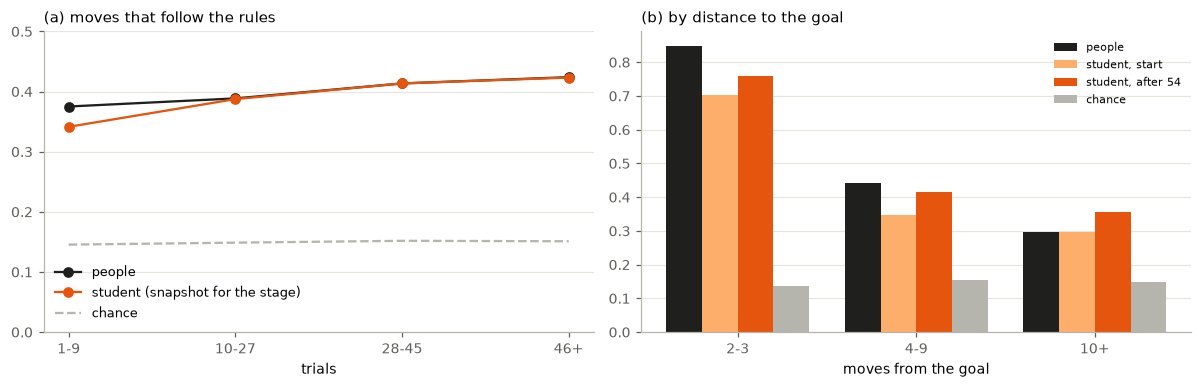

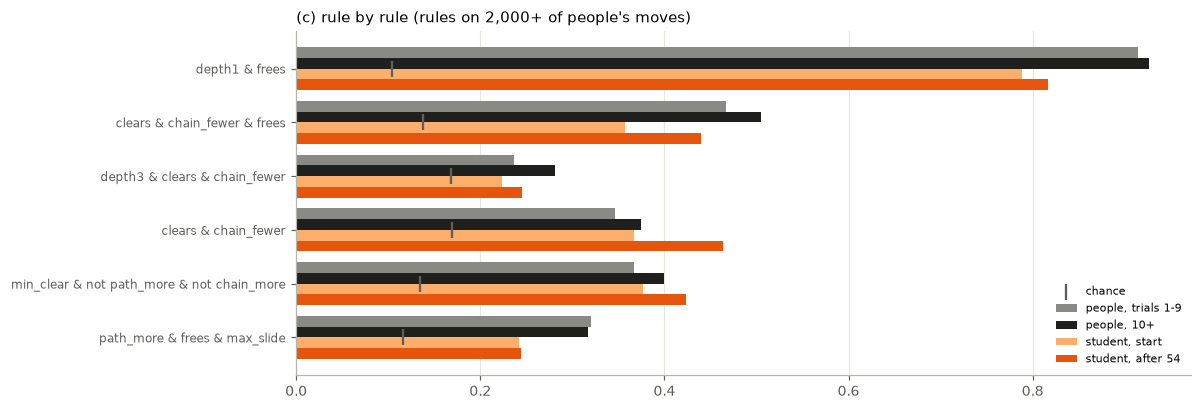

,chance,people,student (paired)
stage,,,
1-9,14.6%,37.5%,34.1%
10-27,14.9%,38.9%,38.8%
28-45,15.2%,41.4%,41.4%
46+,15.1%,42.4%,42.3%


,"people, trials 1-9","people, 10+","student, start","student, after 54",chance,moves
visited rule,,,,,,
depth1 & frees,91%,93%,79%,82%,10%,2144
clears & chain_fewer & frees,47%,50%,36%,44%,14%,9049
depth3 & clears & chain_fewer,24%,28%,22%,25%,17%,7323
clears & chain_fewer,35%,37%,37%,46%,17%,15883
min_clear & not path_more & not chain_more,37%,40%,38%,42%,13%,6809
path_more & frees & max_slide,32%,32%,24%,24%,12%,4489


In [5]:
by_stage = fired.groupby("stage", observed=True).agg(chance=("chance", "mean"), people=("people", "mean"))
by_stage["student (paired)"] = [fired.loc[fired.stage == st, f"net {SNAP_OF[st]}"].mean() for st in STAGES]
by_dist = fired.groupby("dbin", observed=True)[["chance", "people", "net 0", "net 54"]].mean().reindex(["2-3", "4-9", "10+"])
names = dict(enumerate(lists["visited"].rule))
by_rule = fired.assign(early=fired.trial <= 9).groupby(["visited rule", "early"]).people.mean().unstack()
by_rule = pd.DataFrame({"people, trials 1-9": by_rule[True], "people, 10+": by_rule[False],
                        "student, start": fired.groupby("visited rule")["net 0"].mean(),
                        "student, after 54": fired.groupby("visited rule")["net 54"].mean(),
                        "chance": fired.groupby("visited rule").chance.mean(),
                        "moves": fired.groupby("visited rule").size()})
by_rule = by_rule[by_rule.moves >= 2000].rename(index=names)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
ax = axes[0]
x = np.arange(4)
ax.plot(x, by_stage.people, "o-", color=PEOPLE, label="people")
ax.plot(x, by_stage["student (paired)"], "o-", color=NET, label="student (snapshot for the stage)")
ax.plot(x, by_stage.chance, "--", color=CHANCE, label="chance")
ax.set_xticks(x, STAGES)
ax.set_xlabel("trials")
ax.set_ylim(0, 0.5)
ax.set_title("(a) moves that follow the rules")
ax.legend()
ax = axes[1]
x = np.arange(3)
w = 0.2
for k, (col, c, lab) in enumerate([("people", PEOPLE, "people"), ("net 0", "#fdae6b", "student, start"),
                                   ("net 54", NET, "student, after 54"), ("chance", CHANCE, "chance")]):
    ax.bar(x + (k - 1.5) * w, by_dist[col], w, color=c, label=lab)
ax.set_xticks(x, ["2-3", "4-9", "10+"])
ax.set_xlabel("moves from the goal")
ax.set_title("(b) by distance to the goal")
ax.legend(fontsize=7.5)
for a in axes:
    tidy(a)
plt.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(11, 3.8))
y = np.arange(len(by_rule))
for k, (col, c) in enumerate([("people, trials 1-9", "#8a8a85"), ("people, 10+", PEOPLE),
                              ("student, start", "#fdae6b"), ("student, after 54", NET)]):
    ax.barh(y + (k - 1.5) * 0.2, by_rule[col], 0.2, color=c, label=col)
ax.scatter(by_rule.chance, y, marker="|", s=120, color=MUTED, zorder=3, label="chance")
ax.set_yticks(y, by_rule.index, fontsize=8)
ax.invert_yaxis()
ax.set_title("(c) rule by rule (rules on 2,000+ of people's moves)")
ax.legend(fontsize=7, loc="lower right")
tidy(ax, grid="x")
plt.tight_layout()
plt.show()
display(by_stage.style.format("{:.1%}"))
by_rule.style.format({c: "{:.0%}" for c in by_rule.columns if c != "moves"} | {"moves": "{:.0f}"})

- **Both follow the rules far above chance, and more with practice (a).** People go from 37.5% of their moves to
  42.4%. The student's policy, snapshot by stage, goes from 34.1% to 38.8%, 41.4% and 42.3% - after its start,
  within 0.1 points of people at every stage, without ever being told the rules. But section 3 shows this overall
  rate is nearly the same for every student trained on optimal labels, so the match is not evidence for this
  student in particular; the profile by distance (b) is where students differ.
- **Near the goal people already know the key rule; the student never quite does (b, c).** "Move red's blocker so
  red's path opens" is people's move 91-93% of the time from their first trials; the student's policy puts 79% on it
  at the start and 82% after 54 trials. Phase 2's near-goal gap (people near-perfect close to the goal, the student
  middling) is largely this one rule.
- **People's learning is in freeing the car above.** Their clearest gain is on "clears & chain fewer & frees" (47%
  of moves in trials 1-9, 50% after, 53% from trial 28); the student gains there too (36% → 44%).
- **Far from the goal the student follows the rules more than people do** (36% against 30%): trained on
  hindsight-optimal labels, it drifts toward rule moves where people may be exploring or planning in ways these rules
  don't express.
- **Deep-chain moves stay rare for both**: "depth 3 & clears & chain fewer" is 24-30% of people's moves and 22-25%
  of the student's - the moves that need seeing several links down the chain.

## 3. Is the match specific to this student?

Any learner trained on optimal moves should come to follow optimal-ish rules more. The same measure for students
that should *not* match people: the forward student (no AND-OR; it stalls in efficiency), phase 1's intuition-only
student at its fitted multiplier (x10) and at x30 and x120 (learning 3 and 12 times as much per trial), and the
two-mode student in each of its versions (with the dest head; one network; two networks, at two seeds). Each is
scored as above, its snapshot paired with each stage (`python experiments/rule_mining.py specificity`).

In [6]:
spec = pd.read_csv(os.path.join(RULES, "specificity.csv"))
order = ["people", "two-mode, separate (s0)", "two-mode, separate (s1)", "two-mode, shared (s0)", "two-mode, shared (s1)",
         "two-mode, dest head", "forward student", "intuition, x10", "intuition, x30", "intuition, x120"]
overall = spec[spec.by == "all"].pivot(index="who", columns="stage", values="follows").loc[order, STAGES]
f = spec.set_index(["by", "key", "stage", "who"]).follows.unstack("who")
big = spec[(spec.who == "people") & (spec.moves >= 500)].set_index(["by", "key", "stage"]).index
dist = {}
for who in order[1:]:
    d = (f[who] - f["people"]).abs()
    dist[who] = {by: d.loc[by][d.loc[by].index.isin(big[big.get_level_values(0) == by].droplevel(0))].mean()
                 for by in ("all", "distance", "rule")}
overall = overall.join(pd.DataFrame(dist).T.rename(columns=lambda c: f"from people: {c}"))
display(overall.style.format("{:.1%}", subset=STAGES).format("{:.3f}", subset=[c for c in overall if c.startswith("from")]))
by_d = spec[spec.by == "distance"].pivot_table(index="who", columns=["key", "stage"], values="follows")
by_d = by_d.loc[order, [(k, s) for k in ["2-3", "4-9", "10+"] for s in ["1-9", "46+"]]]
by_d.columns = [f"{k} moves out, trials {s}" for k, s in by_d.columns]
by_d.style.format("{:.0%}")

,1-9,10-27,28-45,46+,from people: all,from people: distance,from people: rule
who,,,,,,,
people,37.5%,38.9%,41.4%,42.4%,nan,nan,nan
"two-mode, separate (s0)",35.1%,39.0%,40.6%,41.0%,0.012,0.061,0.065
"two-mode, separate (s1)",35.1%,38.2%,41.0%,41.3%,0.012,0.062,0.063
"two-mode, shared (s0)",34.1%,38.8%,41.4%,42.3%,0.009,0.066,0.069
"two-mode, shared (s1)",34.1%,38.8%,41.5%,41.8%,0.010,0.068,0.068
"two-mode, dest head",32.9%,38.5%,39.9%,41.2%,0.019,0.067,0.080
forward student,32.9%,38.0%,39.7%,39.8%,0.024,0.069,0.078
"intuition, x10",32.9%,37.2%,40.0%,39.5%,0.026,0.068,0.070
"intuition, x30",32.9%,38.5%,40.5%,41.0%,0.018,0.056,0.053


,"2-3 moves out, trials 1-9","2-3 moves out, trials 46+","4-9 moves out, trials 1-9","4-9 moves out, trials 46+","10+ moves out, trials 1-9","10+ moves out, trials 46+"
who,,,,,,
people,82%,86%,42%,46%,28%,31%
"two-mode, separate (s0)",73%,74%,35%,42%,30%,34%
"two-mode, separate (s1)",73%,72%,35%,42%,30%,35%
"two-mode, shared (s0)",70%,75%,34%,42%,29%,36%
"two-mode, shared (s1)",70%,74%,34%,42%,29%,36%
"two-mode, dest head",69%,76%,32%,41%,28%,35%
forward student,69%,74%,32%,40%,28%,33%
"intuition, x10",69%,74%,32%,40%,28%,33%
"intuition, x30",69%,79%,32%,43%,28%,32%


(`from people`: the mean absolute difference from people's rule-following - over the four stages; over stage x
distance cells; over stage x rule cells with 500+ of people's moves.)

- **The overall rate doesn't tell students apart.** Every student rises from about 33% of the policy's probability on
  rule moves to 40-42% - the forward student, which stalls in efficiency, included (33% → 40%). The two-mode
  students are closest to people's 37.5% → 42.4%, but only by 1-2 points (mean distance 0.009-0.019 against
  0.018-0.026). Learning from optimal labels makes a learner follow these rules more almost automatically.
- **The profile by distance does.** People make the rule move 82% of the time 2-3 moves from the goal *in their first
  trials* (86% by trials 46+); every student starts at 69-73%. So the near-goal gap is mostly **knowledge people bring
  with them**, not slower learning - the start was fitted to people's overall efficiency, not to this profile.
- **Only a far faster learner ends at people's profile**: phase 1's student at x120 reaches 82% near the goal, 48%
  mid-puzzle and 31% far by the end (people 86 / 46 / 32), but at 12 times the multiplier fitted to people's
  learning rate. The two-mode student never closes the near-goal gap (about 74% at the end), and far from the goal
  follows the rules a little more than people do.
- **So the rules are a better test as a profile than as a rate**: by distance (and rule by rule), the measure
  separates students that the overall rate can't, and it locates what the student lacks - the near-goal knowledge
  people start with.

## 4. Rules or optimality?

Rule moves are mostly optimal (62% on people's boards, chance 22%), so a learner that finds optimal moves more often
follows the rules more, whatever it is. Splitting each student's choices into optimal and non-optimal ones separates
the two: if rule-following only restates optimality, the share of rule moves among optimal choices (and among
non-optimal ones) is the same for every student and stage. People: their moves; the students: the policy's
probabilities, snapshot paired with the stage (`python experiments/rule_mining.py optimal`).

In [7]:
rvo = pd.read_csv(os.path.join(RULES, "rules_vs_optimal.csv"))
cells = rvo[rvo.distance != "all"]
r = {"all distances": np.corrcoef(cells.optimal, cells.rule)[0, 1]}
r.update({f"{d} moves out": np.corrcoef(g.optimal, g.rule)[0, 1] for d, g in cells.groupby("distance")})
display(pd.Series(r, name="r(P(rule), P(optimal)), student x stage cells").to_frame().style.format("{:.3f}"))
who = ["people", "two-mode, separate (s0)", "forward student", "intuition, x10", "intuition, x120"]
cols = ["optimal", "rule among optimal", "rule among non-optimal"]
show = rvo[rvo.stage.isin(["1-9", "46+"])].pivot_table(index="who", columns=["distance", "stage"], values=cols)
show = show.loc[who, [(c, d, s) for d in ["2-3", "4-9", "10+"] for c in cols for s in ["1-9", "46+"]]]
show.columns = [f"{d}: {c}, {s}" for c, d, s in show.columns]
show.T.style.format("{:.0%}")

,"r(P(rule), P(optimal)), student x stage cells"
all distances,0.968
10+ moves out,0.320
2-3 moves out,0.997
4-9 moves out,0.977


who,people,"two-mode, separate (s0)",forward student,"intuition, x10","intuition, x120"
"2-3: optimal, 1-9",85%,76%,72%,72%,72%
"2-3: optimal, 46+",89%,76%,77%,76%,85%
"2-3: rule among optimal, 1-9",96%,96%,96%,96%,96%
"2-3: rule among optimal, 46+",96%,96%,95%,95%,96%
"2-3: rule among non-optimal, 1-9",3%,2%,1%,1%,1%
"2-3: rule among non-optimal, 46+",5%,5%,3%,4%,4%
"4-9: optimal, 1-9",58%,43%,41%,41%,41%
"4-9: optimal, 46+",66%,52%,50%,51%,65%
"4-9: rule among optimal, 1-9",64%,62%,61%,61%,61%
"4-9: rule among optimal, 46+",63%,64%,63%,63%,64%


- **Near the goal and mid-puzzle, following the rules is choosing optimal moves.** Over every student x stage
  cell, P(rule) tracks P(optimal) at r = 0.997 2-3 moves out and 0.98 at 4-9. Rule moves make up 95-97% of the
  optimal choices near the goal and 60-64% mid-puzzle, for every student at every stage: rule-following rises only
  because optimality does. People's near-goal advantage in the rules (section 3) is their near-goal advantage in
  optimal moves, described in words.
- **Far from the goal (10+ moves) they come apart** (r = 0.32), and the rules carry information optimality doesn't:
  the students' choices lean toward rule-type moves - clear a car, shrink the chain - more than people's, for right
  and wrong moves alike (by trials 46+, rule moves are 44-46% of their optimal choices and 25-27% of their
  non-optimal ones, against people's 42% and 23%). People's far-from-goal optimal moves are more often *not* rule
  moves - plausibly preparatory moves that make room before anything can be cleared - and their mistakes are less
  rule-shaped. The x10 students drift toward greedy chain-clearing as they learn; the x120 student, oddly, stays
  people-like here (40%, 21%).
- **So as markers of progress, the rules are optimality described in words near the goal and mid-puzzle** - useful
  for saying *what* the right moves are, not for telling learners apart; far from the goal, the mix of rule and
  non-rule moves is a specific, testable difference between the student and people.

## 5. Individuals

Does a person who comes to follow the rules more also become more efficient? Per person: rule-following in trials
10+ minus trials 1-9, against moves / optimal (solved) in trials 1-9 minus trials 10+.

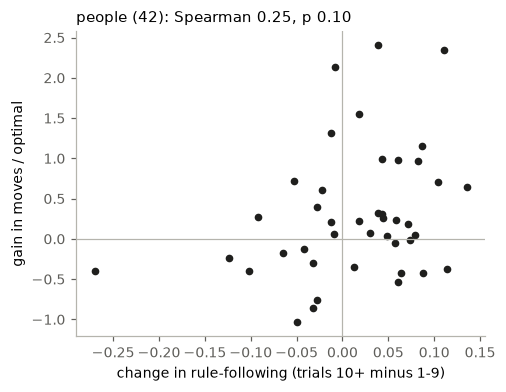

mean change in rule-following +0.014 (sd 0.076)


In [8]:
rho, p = spearmanr(per_person["rule gain"], per_person["efficiency gain"])
fig, ax = plt.subplots(figsize=(4.8, 3.6))
ax.scatter(per_person["rule gain"], per_person["efficiency gain"], s=16, color=PEOPLE)
ax.axvline(0, color=RULE, lw=0.8)
ax.axhline(0, color=RULE, lw=0.8)
ax.set_xlabel("change in rule-following (trials 10+ minus 1-9)")
ax.set_ylabel("gain in moves / optimal")
ax.set_title(f"people ({len(per_person)}): Spearman {rho:.2f}, p {p:.2f}")
tidy(ax, grid=None)
plt.show()
print(f"mean change in rule-following {per_person['rule gain'].mean():+.3f} (sd {per_person['rule gain'].std():.3f})")

People differ a lot in how their rule-following changes (on average +1.4 points, SD 7.6), and those whose
rule-following rose more improved a little more in efficiency - but only weakly (Spearman 0.25, p 0.11, 42 people):
suggestive, not established. The student's 8 copies, which start from the same network, can't show differences like
these.

## 6. What the rules are, and what they are for

**Right now the rules are a lens, not part of the student.** Nothing in the student uses them; they describe, in
words, what its learning (and people's) amounts to. Every student trained on optimal moves comes to follow them, so
they capture something real about the task; what tells a model of *people* apart is the profile - where, by distance
and by rule, it follows them as people do (section 3). Near the goal and mid-puzzle the rules mostly restate
optimality; far from the goal they describe *which kind* of move a learner makes, and there the student is greedier
than people (section 4).

**Ways they could become part of the student**, from least to most change:
1. a **rule mode** in the move-by-move mixture (beside intuition, flat planning and AND-OR), with its weight fitted to
   people's moves - the test of whether people *use* rules rather than rules merely describing good play;
2. **rules as a readable bias on the policy**: the network's score plus a learned weight per rule that fires, so
   learning splits into named rules and what the network does beyond them;
3. **learning rules**: a production-rule learner that keeps or makes rules from the hindsight labels of its solved
   attempts (as ACT-R's production compilation, or Butler et al.'s synthesis run during the session);
4. **rules as a teacher's hints**: saying a rule instead of showing a move - a middle level of help for the
   assistance dilemma.

**Caveats**
- People are scored by the moves they made, the student by its policy's probabilities (intuition, not the two-mode
  student's moves).
- The rules are judged against optimal moves, not human strategies: a person can follow a sensible strategy these
  rules can't express.
- The vocabulary is mine and the search stops at 3 conditions; a richer language might cover the 14-22% of boards
  where no rule fires.
- Rules that fire on few of people's moves have noisy per-stage numbers.

**Reading**: Butler, Torlak & Popović (2017), *Synthesizing interpretable strategies for solving puzzle games*,
FDG '17; McGrath et al. (2022), *Acquisition of chess knowledge in AlphaZero*, PNAS; Schut et al. (2023), *Bridging
the human-AI knowledge gap: concept discovery and transfer in AlphaZero*; Koh et al. (2020), *Concept bottleneck
models*, ICML; Kim et al. (2018), TCAV, ICML; van Opheusden et al. (2023), *Expertise increases planning depth in
human gameplay*, Nature.